---

MRI analysis 

---

In [ ]:
# autoload
%load_ext autoreload
%autoreload 2

# load relevant pgl classes
from pgl import pgl, pglDatabase, pglActions, pglFlywheel, pglAFNI, pglActionsMRI, pglActionsMNE, pglActionsFixes

---

Load behavioral data

---

In [ ]:
pgl.importSettings()

In [ ]:
newSession = pglActions.loadSession.execute()
if newSession: 
    session = newSession
    session.print()

---

Fix missing volume triggers

---

In [ ]:
fixVolumeTimes = pglActionsFixes.fixVolumeTimes()
newSession = fixVolumeTimes.execute(session=session)
if newSession: 
    session = newSession
    session.print()

In [ ]:
session.display()

In [ ]:
session.print()

---

Load data from flywheel

---

In [ ]:
newSession = pglActions.loadFlywheel().execute(session=session, showScanCounts=False)
if newSession: 
    session = newSession
    session.print()

In [ ]:
session.mri.print(match='nsdmini')

---

Align MRI scans with behavior/experiment session data

---

In [ ]:
session.setScanRunMatches([(4, 0), (5, 1), (6, 2), (10, 3), (11, 4), (12, 5), (17,6), (21, 7), (22, 8), (23, 9)])
#session.setScanRunMatches([(4, 0)])

In [ ]:
session.displayScanRunMapping()

---

Save the raw session to database

---

In [ ]:
session.saveRawSession()

---

Help on commands

---

In [ ]:
# Get a list of all actions within an action module
#pglActionsFixes.help()
#pglActions.help()
#pglActionsMNE.help()
pglActionsMRI.help()

In [ ]:
# Get specific help on a paritcular action
help(pglActionsMRI.mriEstimateMotionAFNI)

---

Database

---

In [ ]:
# display database
pglDatabase.print(experimentName='nsd-mini')
#pglDatabase.print()

---

Load a session

---

In [2]:
# load a specific session
#session = pglDatabase.loadSession(126)
#session = pglDatabase.loadSession(128)
session = pglDatabase.loadSession(136)

NameError: name 'pglDatabase' is not defined

---

Display information about a session


---

In [ ]:
# display the top-level information
session.print()

In [ ]:
# more detailed trial-by-trial information, for a particular run
session.print(runNum=0, verbose=True)

In [ ]:
# display mri scans
session.mri.print()

In [ ]:
# display behavioral plots
session.display();

---

Show history of actions

---

In [ ]:
session.history()

In [ ]:
# show more detailed information
session.history(verbose=True)

In [ ]:
# show what products actions produced
session.history(showProducts=True)

In [ ]:
# show the logs for a particular action
session.history(3,showLogs=True)

In [ ]:
# get the products for a particular action and print
motion = session.getProduct("motion")
motion.print()

In [ ]:
# dispaly any plots related to the product
motion.display();

---

AFNI: check availability and optional install

---

In [ ]:
# Install AFNI. If already installed, will not try to re-install but will display information about installation
afni = pglAFNI()
afni.install()

In [ ]:
# check availability of specifc commands
afni = pglAFNI(directory="~/proj/afni/abin")
available = afni.checkAvailable("3dvolreg")

---

Run motion comp

---

In [ ]:
newSession = pglActionsMRI.mriEstimateMotionAFNI().execute(session=session, deferApply=True)
if newSession: session = newSession

In [ ]:
# display matrices
motion = session.getProduct('motion')
if motion: motion.display()

In [ ]:
# display motion correction estimates
session.mri.

In [ ]:
session.saveSession()

In [ ]:
session.print(verbose=True)

In [ ]:
newSession = pglActionsFixes.reconstructVolumeTriggersFromNifti.execute(session=session)
if newSession: session = newSession

In [ ]:
newSession.print()

In [ ]:
session.runs[0].tasks[0].stimulusDatabase.print()

In [ ]:
session.runs[0].getTrialsByStimulus()

In [ ]:
session.saveSession(checkpointName="within motion correction")

In [ ]:
from pgl.pglExternalTools import pglExternalTool, pglAFNI

pglAFNI.configure()

In [ ]:
from pgl import pglExternalTool
reports = pglExternalTool.print()

In [ ]:
from pgl.pglExternalTools import pglMATLAB

reports = pglMATLAB.print(validate=True, timeout=120)

In [ ]:
from pgl.pglExternalTools import pglGLMsingle

pglGLMsingle.configure()

In [6]:
session.setScanRunMatches([(4, 0)])

(pglSession:printScanRunMatches) Scan/run correspondence: 1 matched pairs; indices are zero-based.
(pglSession:printScanRunMatches)   MRI scan 4 (nsdmini_run01_bold_1p4mm_R3x3_esp570_TR1510:
1_3_12_2_1107_5_2_61_251202_2026111312313389043002453_0_0_0.nii.gz) ↔ behavioral run 0
(pglSession:printScanRunMatches)   Unmatched MRI scans: 0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26,
27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47
(pglSession:printScanRunMatches)   Unmatched behavioral runs: 1, 2, 3, 4, 5, 6, 7, 8, 9
(pglSession:printScanRunMatches)   These are acquisition matches only; volume correspondence and clock alignment are separate.
(pglSession:setScanRunMatches) Correspondence updated in memory. Use saveSession() to preserve matches with the session's MRI, behavioral contents, and
derived products.


[(4, 0)]

             0% [   00:00<       ?] GLMsingle

Action console logs: /Users/justin/.cache/pgl/actionLogs/python-6qh2msf9
(GLMsingle:_run) GLMsingle analysis: 'GLMsingleTypeBTest'
Explicit model: B — HRF fitting, without GLMdenoise or fractional ridge.
Inputs: current committed MRI images, otherwise acquisitions.
Outputs: analysis matrices; current MRI images will not be replaced.
(GLMsingle:_prepareInputs) GLMsingle inputs: 1 runs; 74 stimuli; 103 presentations (45 stimuli 1x, 29 stimuli 2x)
(GLMsingle:_prepareInputs) Conditions shared across runs: 0; identity: recorded source image
(GLMsingle:_prepareInputs) TR: 1.51 s; stimulus duration: 2 s; onsets: segment 0 (zero-based)
(GLMsingle:_prepareInputs) Voxels per run: 1990656; spatial shape: (144, 144, 96); volumes per run: [241]
(GLMsingle:_prepareInputs) Presentations per run: [103]
(GLMsingle:_fitPreparedInputs) GLMsingle 1.2: /Users/justin/miniforge3/envs/pgl_mri/lib/python3.12/site-packages/glmsingle/glmsingle.py
Workspace: /Users/justin/.cache/pgl/glmsingle/fit-0ln6ufwe
Model: 

/Users/justin/miniforge3/envs/pgl_mri/lib/python3.12/site-packages/glmsingle/glmsingle.py:669: UserWarning: None of your conditions occur in more than one run. Are you sure this is what you intend?
  warnings.warn(msg)


*** Saving design-related results to /Users/justin/.cache/pgl/glmsingle/fit-0ln6ufwe/outputs/DESIGNINFO.npy. ***
*** FITTING DIAGNOSTIC RUN-WISE FIR MODEL ***
*** Saving FIR results to /Users/justin/.cache/pgl/glmsingle/fit-0ln6ufwe/outputs/RUNWISEFIR.npy. ***

*** FITTING TYPE-A MODEL (ONOFF) ***

fitting model...
done.

preparing output...
done.

computing model fits...
done.

computing R^2...
done.

computing SNR...
done.



/Users/justin/miniforge3/envs/pgl_mri/lib/python3.12/site-packages/sklearn/mixture/_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


*** Setting brain R2 threshold to 0.5812986944162574 ***

*** FITTING TYPE-B MODEL (FITHRF) ***



chunks: 100%|██████████| 40/40 [04:05<00:00,  6.14s/it]


*** All model types done ***

*** return model types in results ***

(GLMsingle:_convertTypeBResults) GLMsingle typea.betasmd: retaining 21 nonfinite output values without replacement.
(GLMsingle:_convertTypeBResults) GLMsingle typea.onoffR2: retaining 21 nonfinite output values without replacement.
(GLMsingle:_convertTypeBResults) GLMsingle typeb.betasmd: retaining 2163 nonfinite output values without replacement.
(GLMsingle:_convertTypeBResults) GLMsingle typeb.R2: retaining 21 nonfinite output values without replacement.
(GLMsingle:_convertTypeBResults) GLMsingle typeb.R2run: retaining 21 nonfinite output values without replacement.
(GLMsingle:_convertTypeBResults) GLMsingle typeb.FitHRFR2: retaining 420 nonfinite output values without replacement.
(GLMsingle:_convertTypeBResults) GLMsingle typeb.FitHRFR2run: retaining 420 nonfinite output values without replacement.
(GLMsingle:_convertTypeBResults) Validated GLMsingle Type B dimensions and mappings: 1990656 voxels; 103 chronologica

<Figure size 1100x1200 with 0 Axes>

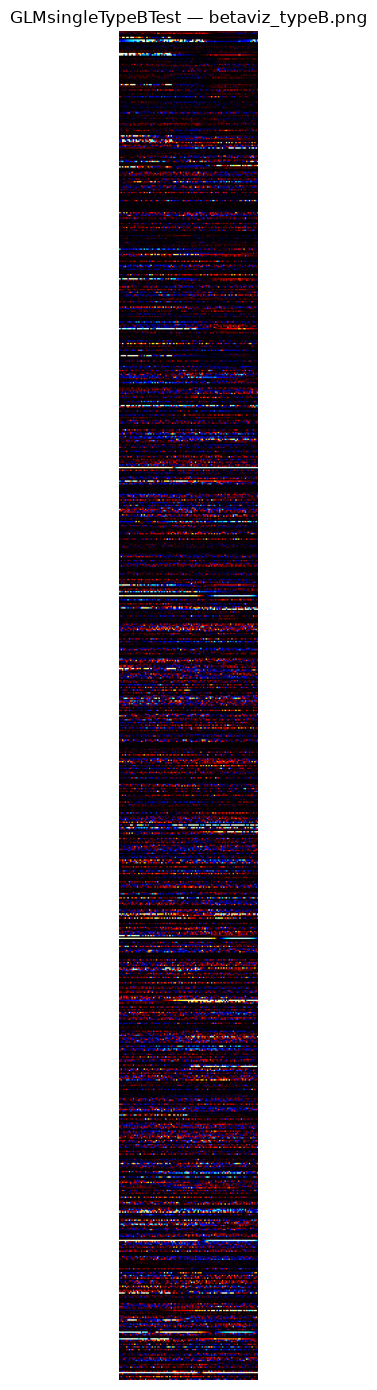

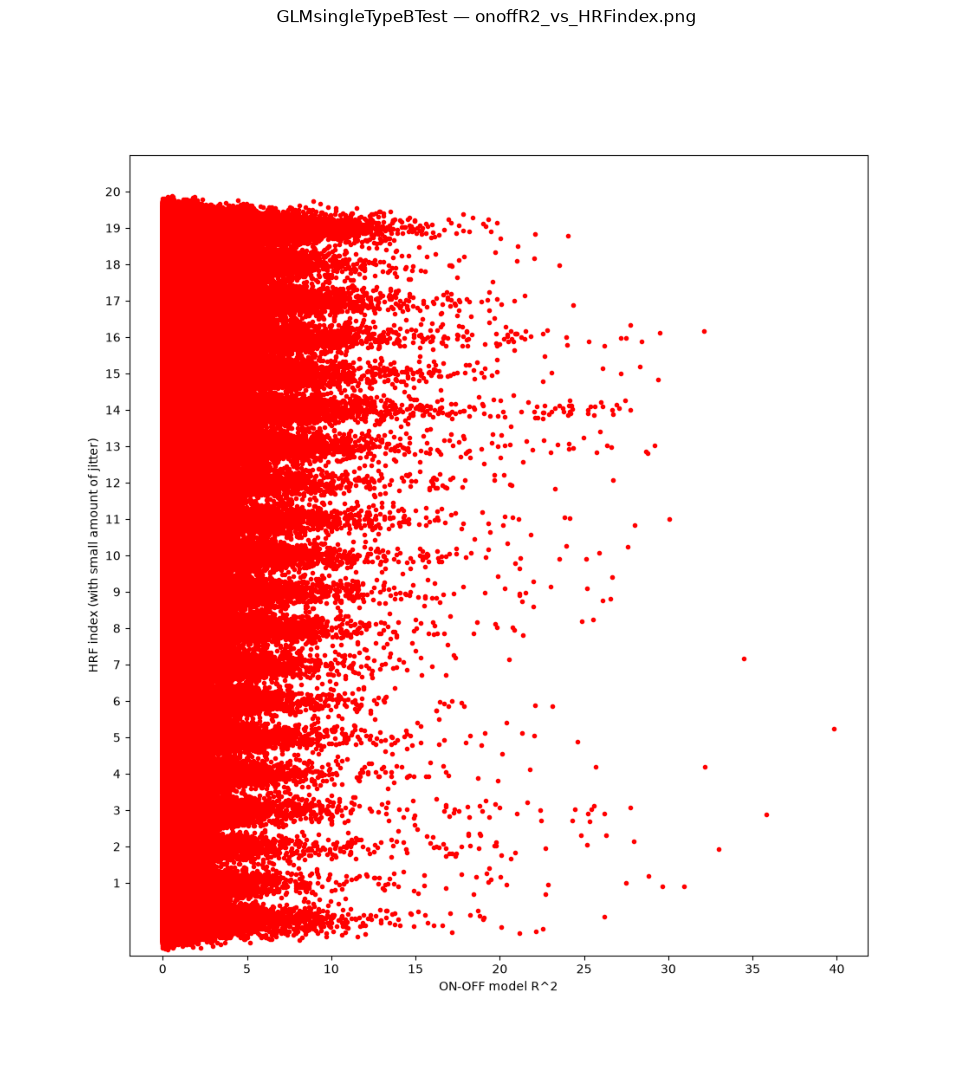

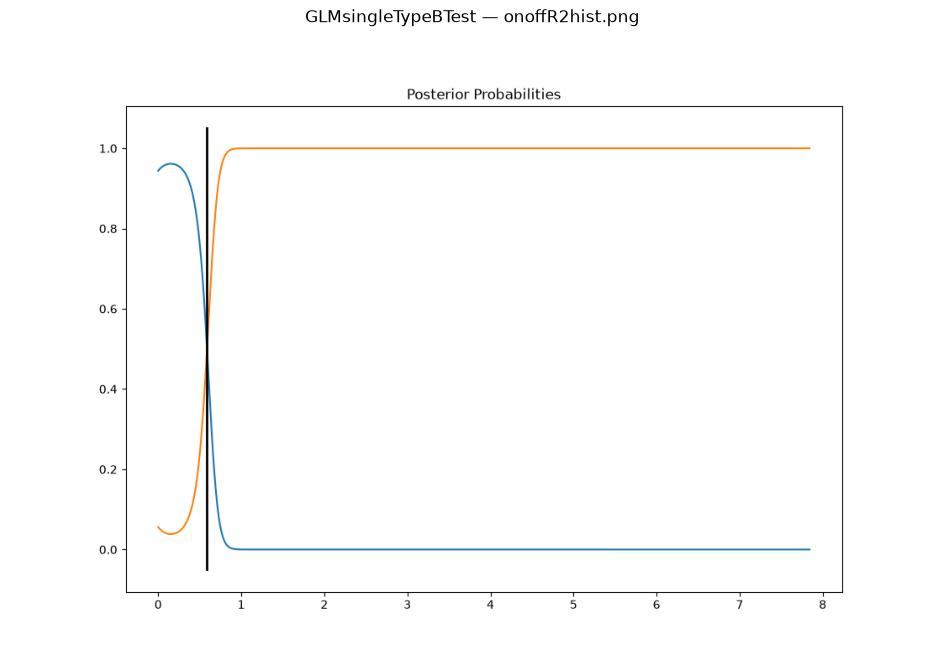

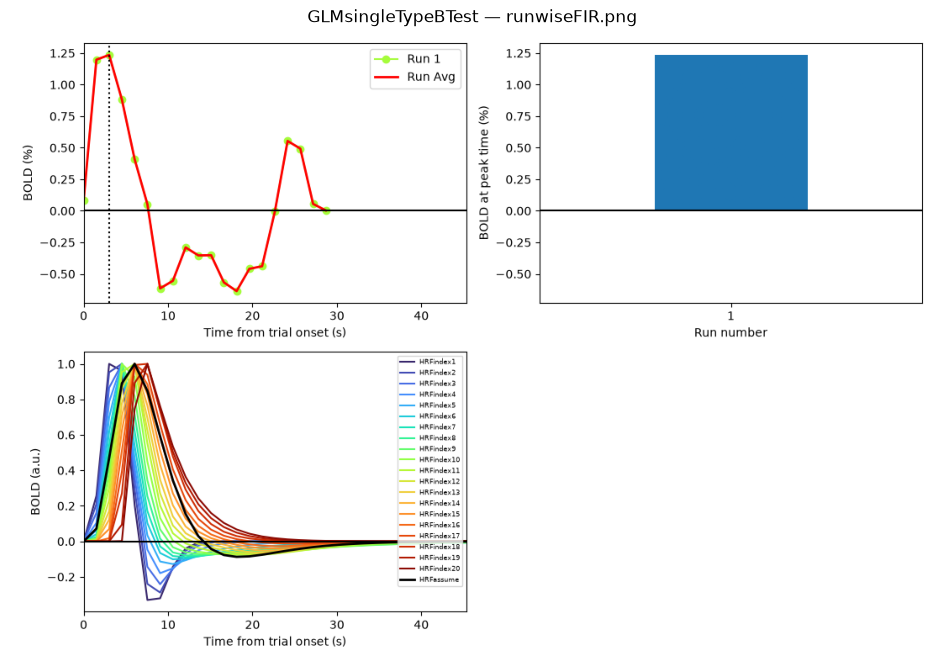

In [7]:
from pgl.pglActionsMRI import pglActionsMRI
from pgl.pglDatabase import pglDatabase

#session = pglDatabase.loadSession(136)
#session.setScanRunMatches([(4, 0), (5, 1)])

newSession = pglActionsMRI.GLMsingle.execute(session=session, model="B", scanIndices=[4], stimDur=2.0, outputName="GLMsingleTypeBTest")
if newSession: session = newSession

In [15]:
session.history()

Failed to reload module 'pgl.pglPipeline' from file '/Users/justin/proj/pgl/pgl/pglPipeline.py'
Traceback (most recent call last):
  File "/Users/justin/miniforge3/envs/pgl_mri/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 325, in check
    superreload(m, reload, self.old_objects)
  File "/Users/justin/miniforge3/envs/pgl_mri/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 584, in superreload
    module = reload(module)
             ^^^^^^^^^^^^^^
  File "/Users/justin/miniforge3/envs/pgl_mri/lib/python3.12/importlib/__init__.py", line 131, in reload
    _bootstrap._exec(spec, module)
  File "<frozen importlib._bootstrap>", line 866, in _exec
  File "<frozen importlib._bootstrap_external>", line 995, in exec_module
  File "<frozen importlib._bootstrap_external>", line 1133, in get_code
  File "<frozen importlib._bootstrap_external>", line 1063, in source_to_code
  File "<frozen importlib._bootstrap>", line 488, in _call_with_frames_removed
  

================================ action history ================================
0: loadSession ran at 21:28:28 11/17/2026 with status: SUCCESS duration: 275ms
1: loadFlywheel ran at 21:29:07 11/17/2026 with status: SUCCESS duration: 257ms
2: mriEstimateMotionAFNI ran at 07:13:36 11/19/2026 with status: SUCCESS duration: 2 hours 20 mins 57s | 120 archived log(s)
3: reconstructVolumeTriggersFromNifti ran at 22:45:56 11/19/2026 with status: SUCCESS duration: 277ms
4: mriApplyTransforms ran at 21:00:05 11/20/2026 with status: SUCCESS duration: 22 mins 53s | 2 archived log(s)
5: GLMsingle ran at 14:12:14 11/21/2026 with status: SUCCESS duration: 5 mins 28s | 2 archived log(s)


[autoreload of pgl.pglPipeline failed: Traceback (most recent call last):
  File "/Users/justin/miniforge3/envs/pgl_mri/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 325, in check
    superreload(m, reload, self.old_objects)
  File "/Users/justin/miniforge3/envs/pgl_mri/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 584, in superreload
    module = reload(module)
             ^^^^^^^^^^^^^^
  File "/Users/justin/miniforge3/envs/pgl_mri/lib/python3.12/importlib/__init__.py", line 131, in reload
    _bootstrap._exec(spec, module)
  File "<frozen importlib._bootstrap>", line 866, in _exec
  File "<frozen importlib._bootstrap_external>", line 995, in exec_module
  File "<frozen importlib._bootstrap_external>", line 1133, in get_code
  File "<frozen importlib._bootstrap_external>", line 1063, in source_to_code
  File "<frozen importlib._bootstrap>", line 488, in _call_with_frames_removed
  File "/Users/justin/proj/pgl/pgl/pglPipeline.py", line 93

In [12]:
session.history(showProducts=True)
product = session.getProduct('GLMsingleTypeBTest')

================================ action history ================================
0: loadSession ran at 21:28:28 11/17/2026 with status: SUCCESS duration: 275ms
1: loadFlywheel ran at 21:29:07 11/17/2026 with status: SUCCESS duration: 257ms
2: mriEstimateMotionAFNI ran at 07:13:36 11/19/2026 with status: SUCCESS duration: 2 hours 20 mins 57s | 120 archived log(s)
    rigidMotion          1  names=motion; backend=AFNI; operation=withinRunMotion
    logs               120  stdout=60, stderr=60
    Inspect/get: session.printDataProducts(2)
3: reconstructVolumeTriggersFromNifti ran at 22:45:56 11/19/2026 with status: SUCCESS duration: 277ms
4: mriApplyTransforms ran at 21:00:05 11/20/2026 with status: SUCCESS duration: 22 mins 53s | 2 archived log(s)
    image                1  names=motionCorrectedZarr; operation=withinRunMotionApplication
    logs                 2  stdout=1, stderr=1
    Inspect/get: session.printDataProducts(4)
5: GLMsingle ran at 14:12:14 11/21/2026 with status: SUCCES

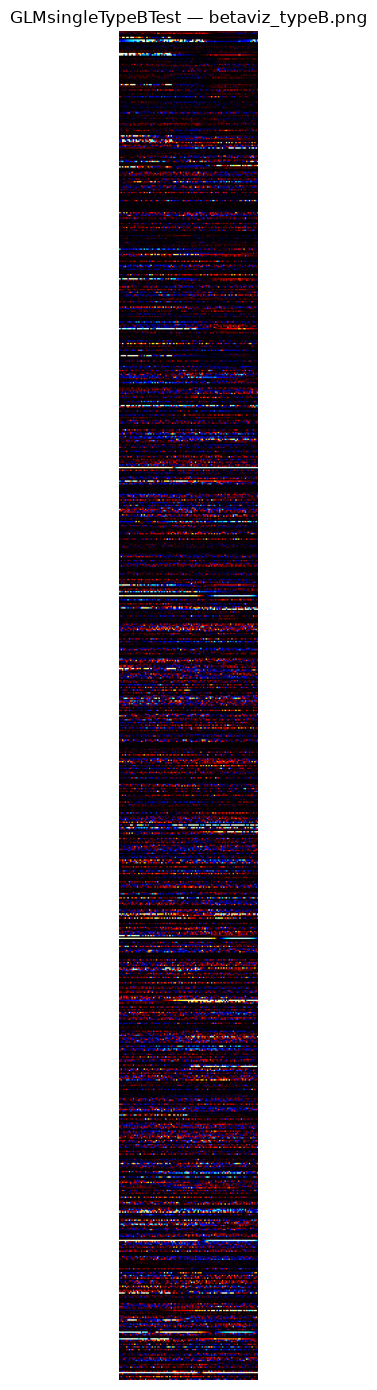

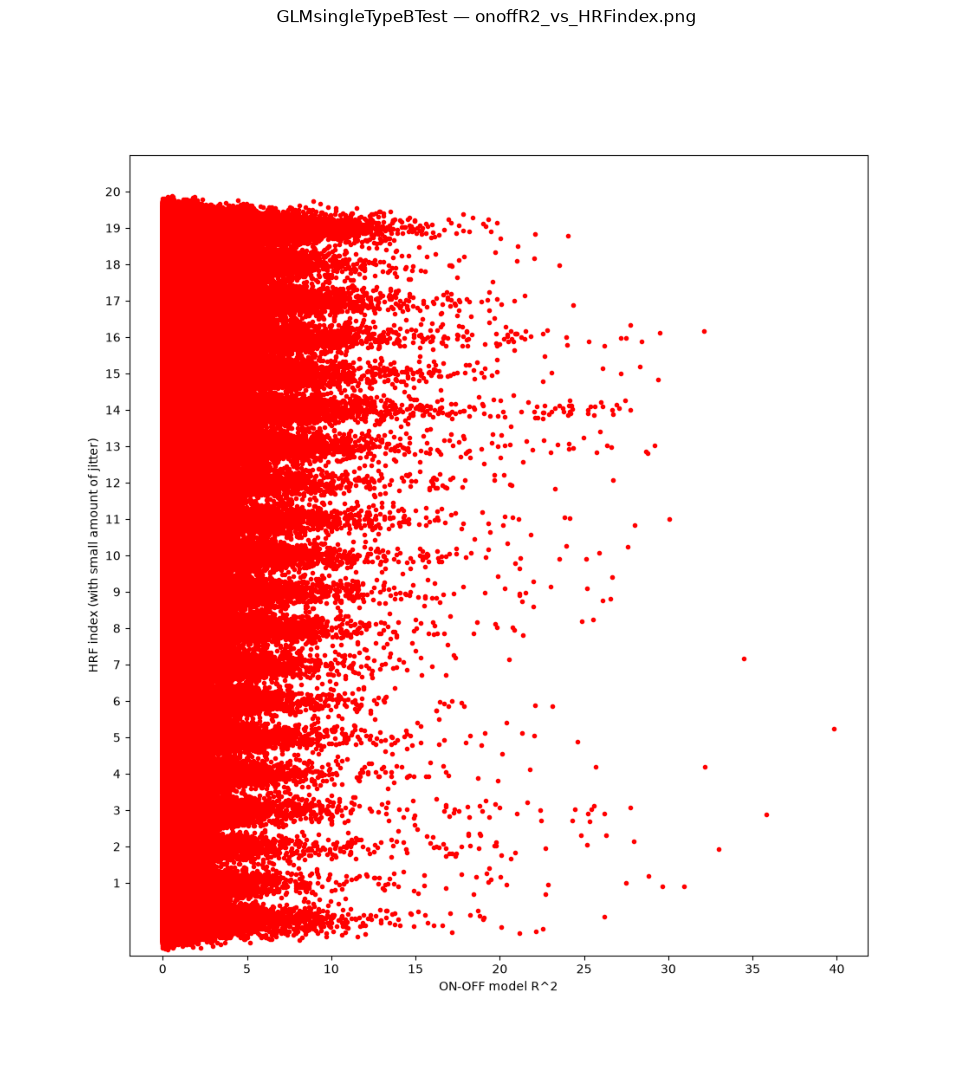

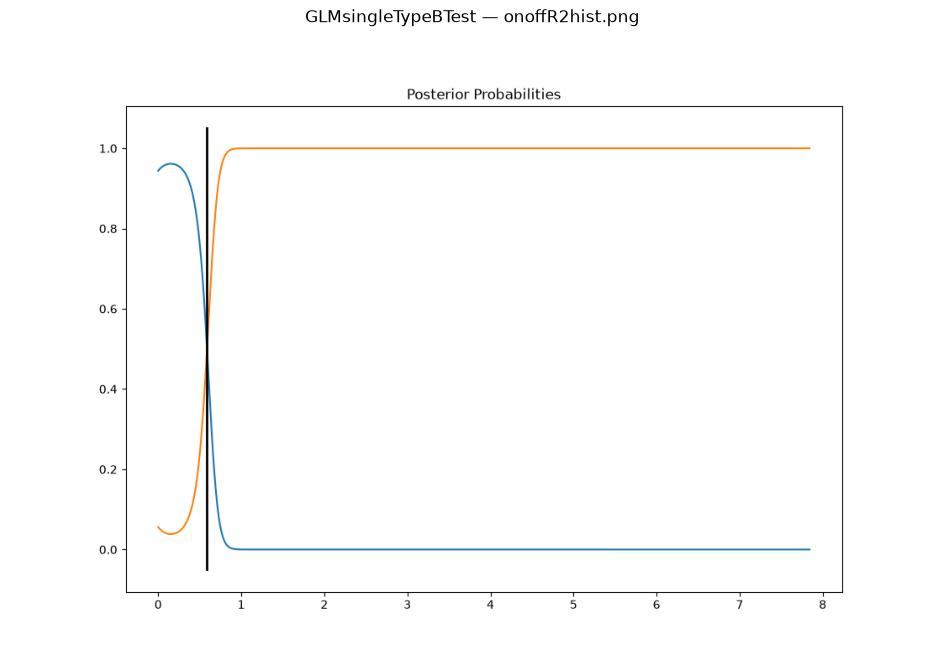

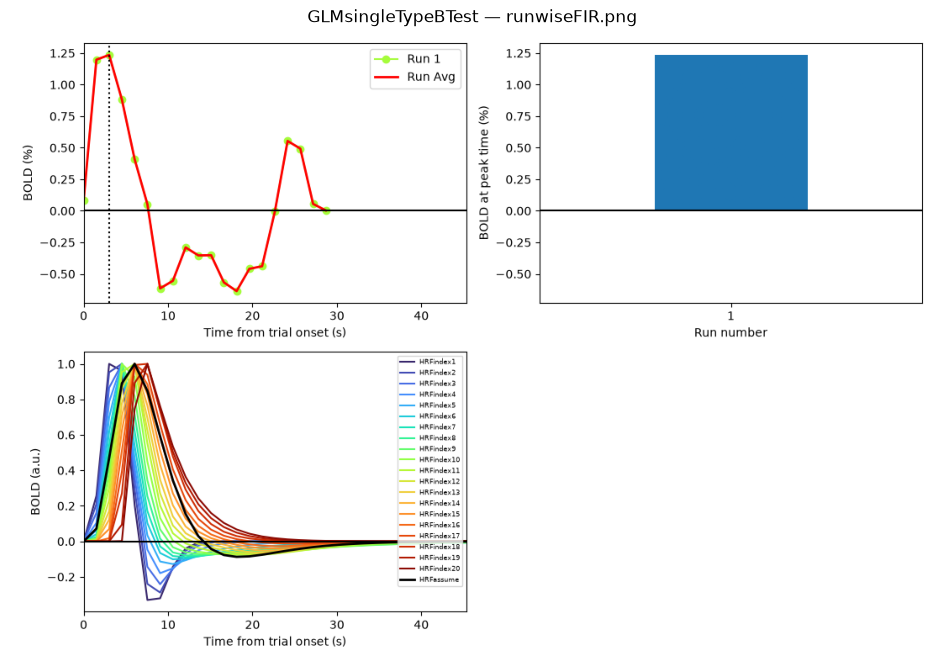

[<Figure size 1000x1400 with 1 Axes>,
 <Figure size 1000x1090.91 with 1 Axes>,
 <Figure size 1000x681.818 with 1 Axes>,
 <Figure size 1000x681.818 with 1 Axes>]

In [14]:
product.display()

In [ ]:
from pgl.pglActionsMRI import pglActionsMRI
from pgl.pglDatabase import pglDatabase

session = pglDatabase.loadSession(136)
session.setScanRunMatches([(4, 0)])

session = pglActionsMRI.GLMsingle.execute(session=session,model="B", scanIndices=[4], stimDur=2.0, outputName="GLMsingleTypeBTest")

In [ ]:
def testGenericProductDisplay():
    import tempfile
    from pathlib import Path
    from types import SimpleNamespace

    import matplotlib.pyplot as plt
    import numpy as np

    from pgl.pglPipeline import pglAction, pglDerivedProduct

    class TestAction(pglAction):
        @classmethod
        def displayProduct(cls, product, **options):
            return super().displayProduct(product, **options)

    # Test double supplies a local image without needing a session fixture.
    # Actual attachment verification is still exercised by the real-session test.
    class TestProduct(pglDerivedProduct):
        def __init__(self, imagePath):
            self._record = {
                "name": "displayTest",
                "kind": "genericImageTest",
                "metadata": {},
                "artifacts": {"testImage.png": {"attachmentName": "testImage.png"}},
            }
            self.imagePath = imagePath
            self.owner = SimpleNamespace(derivedFiles={"testImage.png": {"mediaType": "image/png"}})

        def _requireOwner(self, session=None):
            return self.owner

        def _findProducingAction(self, owner):
            return SimpleNamespace(actionCode={})

        def getFile(self, session=None, role=None, *, cacheDirectory=None):
            assert role == "testImage.png"
            return self.imagePath

    figures = []
    try:
        with tempfile.TemporaryDirectory(prefix="pgl_display_test_") as directory:
            path = Path(directory) / "testImage.png"
            plt.imsave(path, np.arange(100).reshape(10, 10), cmap="gray")
            product = TestProduct(path)

            genericFigures = product.display(show=False)
            assert isinstance(genericFigures, list) and len(genericFigures) == 1
            figures.extend(genericFigures)

            selectedFigures = product.display(role="testImage.png", show=False)
            assert isinstance(selectedFigures, list) and len(selectedFigures) == 1
            figures.extend(selectedFigures)

            overrideFigures = TestAction.displayProduct(product, show=False)
            assert isinstance(overrideFigures, list) and len(overrideFigures) == 1
            figures.extend(overrideFigures)

        print("PASS: generic image display, explicit image selection, and subclass super() delegation.")
        print("No MRI data loaded and no analysis run.")

    finally:
        for figure in figures: plt.close(figure)


testGenericProductDisplay()